# Dataset Import

Connect the Google Drive to the notebook

In [3]:
import os
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [4]:
os.chdir("/content/drive/MyDrive/dataset")

In [ ]:
!pwd

/content/drive/.shortcut-targets-by-id/1NXU303Jgc2_IKKfoQvUhUL3zarWcR-bv/dataset


In [ ]:
!ls

 Clothing1M  'Hotel ID'   Hotels-50k   Receipts  'selfie dataset'   Weapon


## Food 101

Jiawei Sun

**Tutorial:** https://datasets.activeloop.ai/docs/ml/datasets/food-101-dataset/

In [ ]:
!pip install deeplake

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 586.6/586.6 kB 12.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.3/139.3 kB 20.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.1/82.1 kB 10.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 65.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 65.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 16.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.1/76.1 kB 8.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.9/11.9 MB 90.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.3/139.3 kB 18.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.1/82.1 kB 11.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8

In [ ]:
import deeplake
food_101 = deeplake.load('hub://activeloop/food-101-dataset-train')

Opening dataset in read-only mode as you don't have write permissions.


/

This dataset can be visualized in Jupyter Notebook by ds.visualize() or at https://app.activeloop.ai/activeloop/food-101-dataset-train



|

hub://activeloop/food-101-dataset-train loaded successfully.



In [ ]:
dataloader = food_101.pytorch(num_workers=0, batch_size=4, shuffle=False)

/usr/local/lib/python3.10/dist-packages/deeplake/integrations/pytorch/common.py:137: UserWarning: Decode method for tensors ['images'] is defaulting to numpy. Please consider specifying a decode_method in .pytorch() that maximizes the data preprocessing speed based on your transformation.
  warnings.warn(


## Weapon

Jiawei Sun

### Pistol Classification

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
pistol_classification = './Weapon/Pistol_classification'

In [ ]:
# Initialize lists to store file paths and labels
pistol_class_img_path = []
pistol_class_label = []

# Loop through each subfolder in the base directory
for folder_name in os.listdir(pistol_classification):
    folder_path = os.path.join(pistol_classification, folder_name)
    if os.path.isdir(folder_path):
        for image_filename in os.listdir(folder_path):
            # Construct the full path to the image file
            image_path = os.path.join(folder_path, image_filename)
            # Append the image path and label to the lists
            pistol_class_img_path.append(image_path)
            pistol_class_label.append(folder_name)

In [ ]:
# Convert labels to a numerical format
le = LabelEncoder()
numerical_labels = le.fit_transform(pistol_class_label)

# Split the dataset
train_images, val_images, train_labels, val_labels = train_test_split(
    pistol_class_img_path,
    numerical_labels,
    test_size=0.2,  # 20% for validation
    stratify=numerical_labels,  # Stratify split according to the labels
    random_state=42  # Seed for reproducibility
)

# Now you can create your ImageDataGenerators for training and validation
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

## IJB-C


"*NIST HAS DISCONTINUED DISTRIBUTION OF ALL THREE IJB CHALLENGES (IJB-A, IJB-B, AND IJB-C) ON MARCH 14TH 2023.*"


Original link: https://www.nist.gov/itl/iad/ig/ijb-c-dataset-request-form

## International Tourism Receipts

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
receipts_df = pd.read_csv('/content/drive/MyDrive/dataset/Receipts/tourism-recipts.csv')
print(receipts_df.head())

          name code  year      value_$
0  Afghanistan  AFG  2008   57000000.0
1  Afghanistan  AFG  2009   89000000.0
2  Afghanistan  AFG  2010  147000000.0
3  Afghanistan  AFG  2011  165000000.0
4  Afghanistan  AFG  2012  167000000.0


In [7]:
# obtaining the lines for years 1995 to 2020
year_df_list = []
for year in range(1995, 2021):
    year_df_list.append(receipts_df[receipts_df["year"] == year].reset_index(drop = True))
year_df_list[ : 3]

[                                  name code  year       value_$
 0                              Albania  ALB  1995  7.000000e+07
 1                               Angola  AGO  1995  2.700000e+07
 2                            Argentina  ARG  1995  2.550000e+09
 3                              Armenia  ARM  1995  1.400000e+07
 4                                Aruba  ABW  1995  5.540000e+08
 ..                                 ...  ...   ...           ...
 134                            Uruguay  URY  1995  7.250000e+08
 135  Venezuela, Bolivarian Republic of  VEN  1995  9.950000e+08
 136            Virgin Islands, British  VGB  1995  2.110000e+08
 137               Virgin Islands, U.S.  VIR  1995  8.220000e+08
 138                           Zimbabwe  ZWE  1995  1.450000e+08
 
 [139 rows x 4 columns],
                                   name code  year       value_$
 0                              Albania  ALB  1996  9.400000e+07
 1                               Angola  AGO  1996  3.800000e+0

In [8]:
def graph_years_top_spending_countries(years_df: pd.DataFrame, num_top_countries: int, axes = None):
    """ function which produces the bar graph for top num_top_countries in terms
    of receipt value for a given year """

    # if no axes provided, use default ones
    if axes == None:
        plt.figure(figsize = (12, 8))  # Specify your desired figure size here
        axes = plt.gca()

    # adjusting years_df if it is too large
    num_unique_countries = years_df['name'].nunique()
    num_top_countries = min(num_top_countries, num_unique_countries)

    # obtaining averages and sorting
    avg_spending = years_df.groupby('name')['value_$'].mean().reset_index()
    top_avg_spending_sorted = avg_spending.sort_values('value_$', ascending = False).head(num_top_countries)

    # graphing the results
    axes.bar(top_avg_spending_sorted['name'], top_avg_spending_sorted['value_$'])
    axes.set_xlabel('country name')
    axes.set_ylabel('avg receipts in $')
    axes.set_title(f'Top {num_top_countries} Spending Countries in {years_df["year"][0]}')
    axes.tick_params(axis = 'x', rotation = 60)


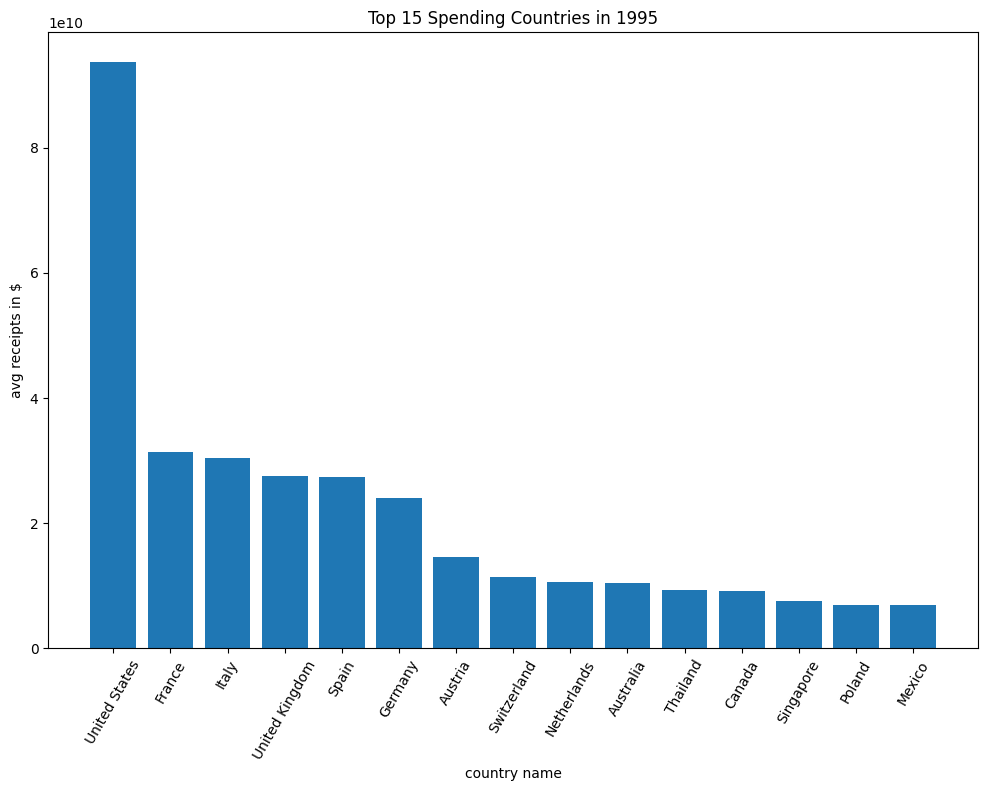

In [9]:
# testing graph_years_top_spending_countries
graph_years_top_spending_countries(year_df_list[0], 15)

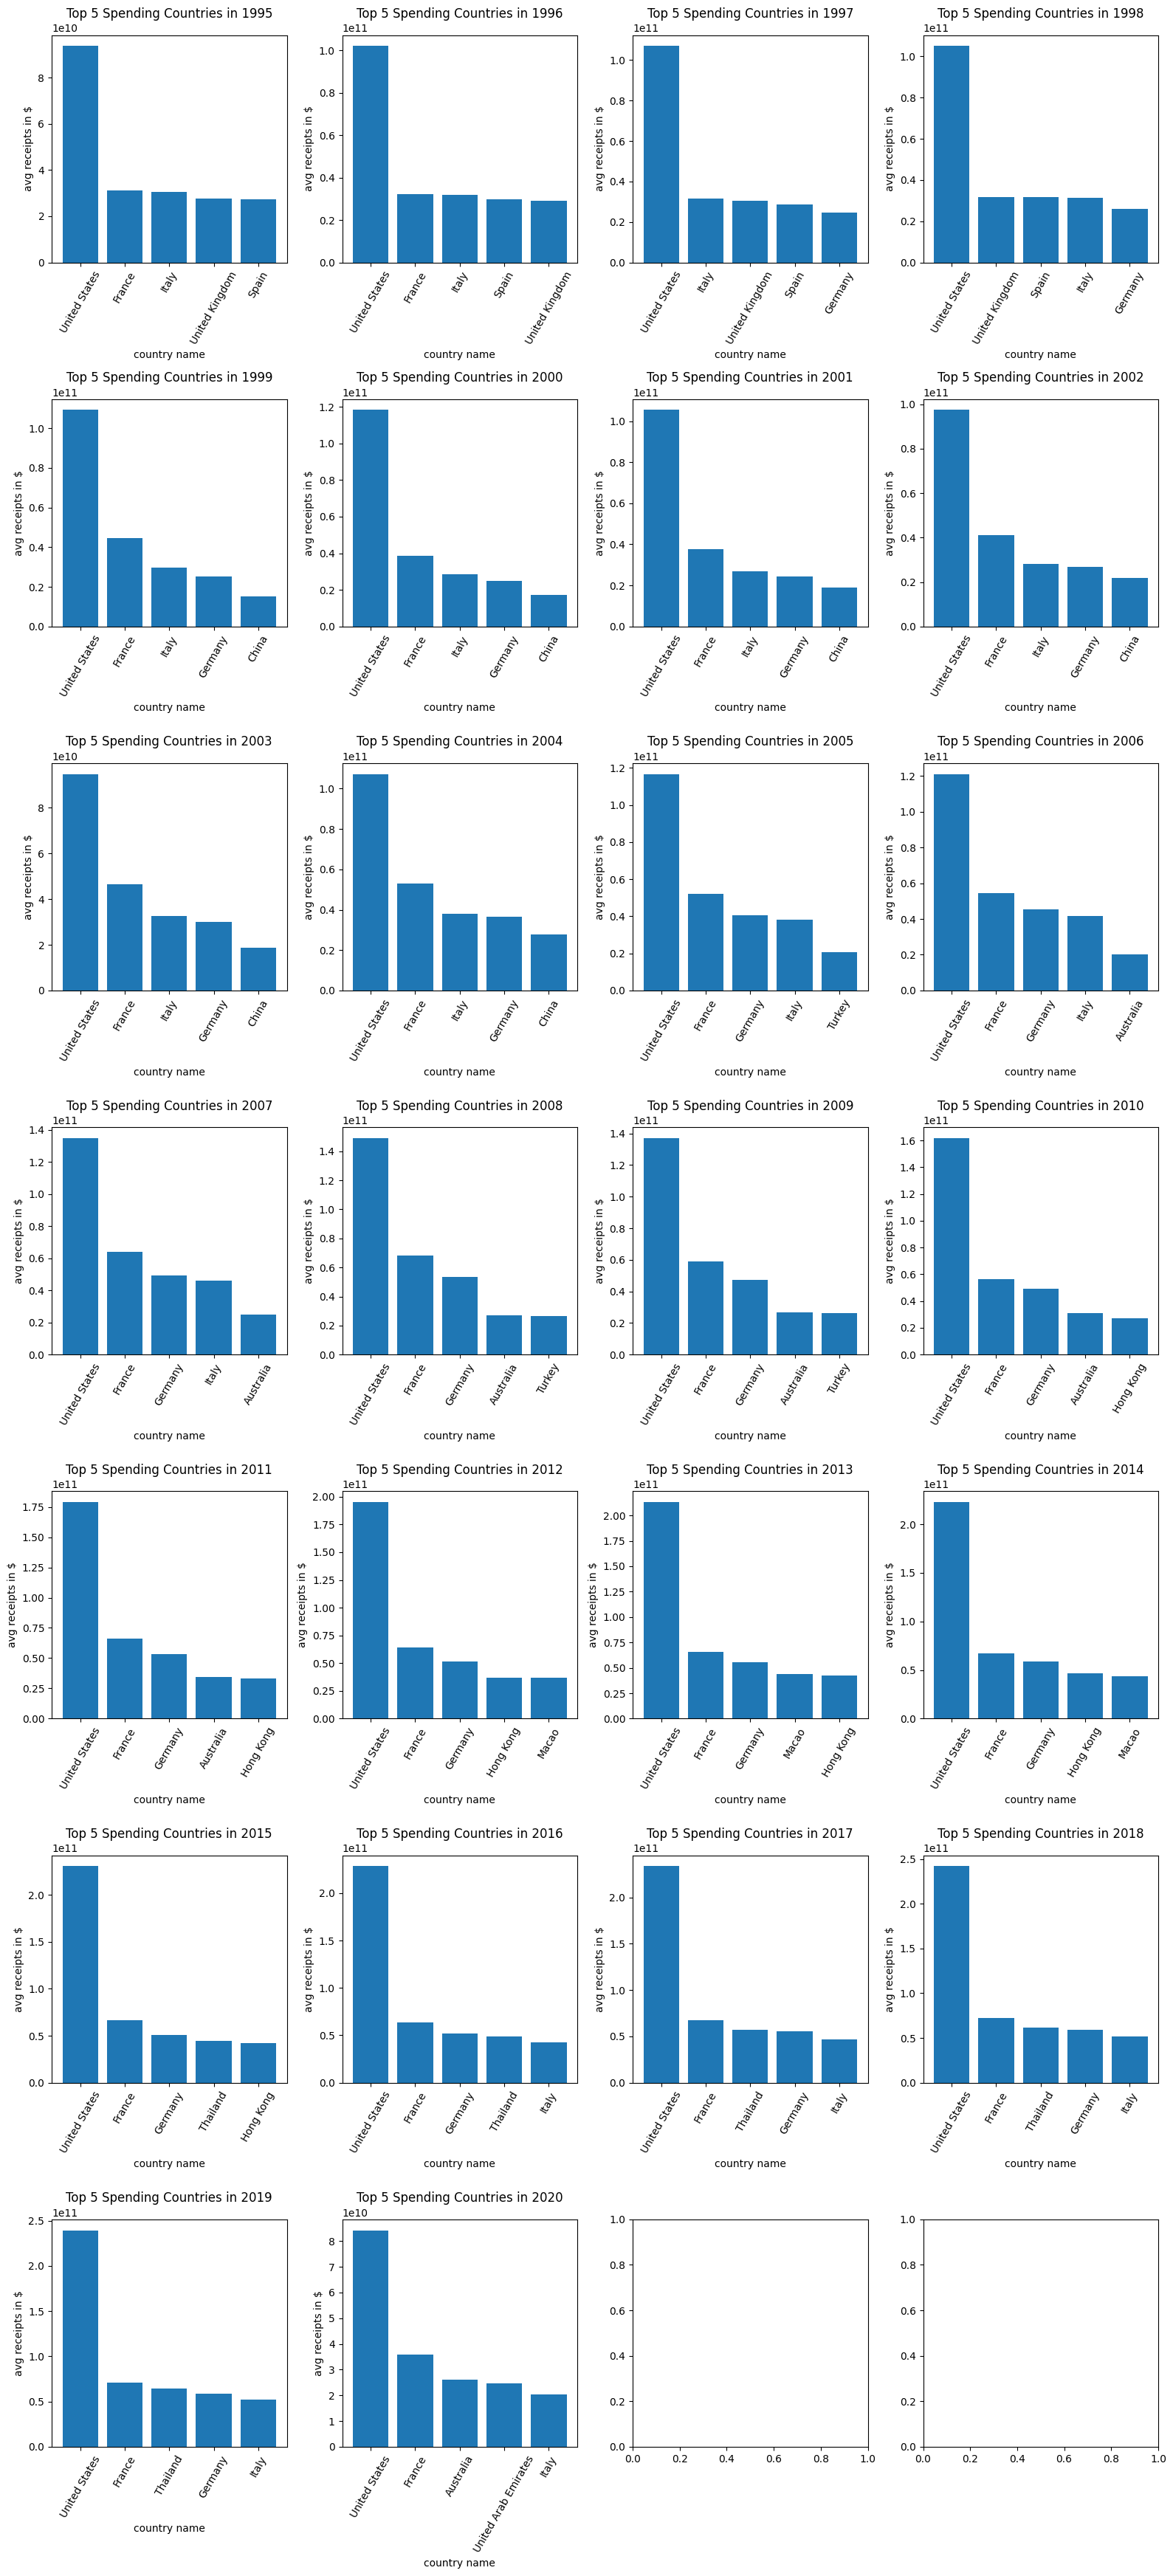

In [20]:
# generating grid for receipt graphs for each year
num_cols = 4
num_rows = len(year_df_list) // num_cols
if num_rows * num_cols != len(year_df_list):
    num_rows += 1

# creating a grid
fig, axs = plt.subplots(num_rows, num_cols, figsize = (num_cols * 4, num_rows * 5))

# filling in the cells
for i, year in enumerate(range(1995, 2021)):
    row = i // num_cols
    col = i % num_cols
    graph_years_top_spending_countries(year_df_list[i], 5, axes = axs[row, col])

# showing the grid
plt.tight_layout()
plt.show()

# Model training

## Weapon

Jiawei Sun

### Pistol Classfication

In [ ]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import load_img, img_to_array

In [ ]:
def load_and_preprocess_image(image_path):
    img = load_img(image_path, target_size=(224, 224))  # Resize image
    img = img_to_array(img)
    img /= 255.0  # Normalize image
    return img

In [ ]:
# Define a simple CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(len(np.unique(numerical_labels)), activation='softmax')  # Number of classes
])

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])


In [ ]:
# Train the model using a custom data generator
def custom_data_generator(pistol_class_img_path, pistol_class_label, batch_size):
    while True:
        batch_paths = np.random.choice(a=pistol_class_img_path, size=batch_size)
        batch_input = []
        batch_output = []

        for input_path in batch_paths:
            input = load_and_preprocess_image(input_path)
            output = pistol_class_label[pistol_class_img_path.index(input_path)]

            batch_input.append(input)
            batch_output.append(output)

        batch_x = np.stack(batch_input, axis=0)  # Use np.stack instead of np.array
        batch_y = np.array(batch_output)

        yield batch_x, batch_y

# Training the model with a custom generator
batch_size = 32
train_generator = custom_data_generator(train_images, train_labels, batch_size)
val_generator = custom_data_generator(val_images, val_labels, batch_size)

steps_per_epoch = len(train_images) // batch_size
validation_steps = len(val_images) // batch_size

model.fit(train_generator, steps_per_epoch=steps_per_epoch, epochs=10, validation_data=val_generator, validation_steps=validation_steps)

Epoch 1/10
246/246 [==============================] - 2675s 11s/step - loss: 4.1353 - accuracy: 0.1419 - val_loss: 3.6092 - val_accuracy: 0.2859
Epoch 2/10
246/246 [==============================] - 1117s 5s/step - loss: 3.6159 - accuracy: 0.2387 - val_loss: 3.3809 - val_accuracy: 0.2982
Epoch 3/10
246/246 [==============================] - 848s 3s/step - loss: 3.4411 - accuracy: 0.2706 - val_loss: 3.2059 - val_accuracy: 0.3171
Epoch 4/10
246/246 [==============================] - 803s 3s/step - loss: 3.3003 - accuracy: 0.2854 - val_loss: 3.0407 - val_accuracy: 0.3504
Epoch 5/10
246/246 [==============================] - 794s 3s/step - loss: 3.1808 - accuracy: 0.3023 - val_loss: 3.0140 - val_accuracy: 0.3648
Epoch 6/10
246/246 [==============================] - 786s 3s/step - loss: 3.0153 - accuracy: 0.3266 - val_loss: 2.8620 - val_accuracy: 0.3883
Epoch 7/10
246/246 [==============================] - 784s 3s/step - loss: 2.9892 - accuracy: 0.3309 - val_loss: 2.9697 - val_accuracy: 0.3